<a href="https://colab.research.google.com/github/Janani-hari/BMSCE-DATA-VISUALIZATION/blob/main/Data_Visulization_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (569, 30) (569 samples, 30 continuous features)
Class Distribution:
 Diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64 



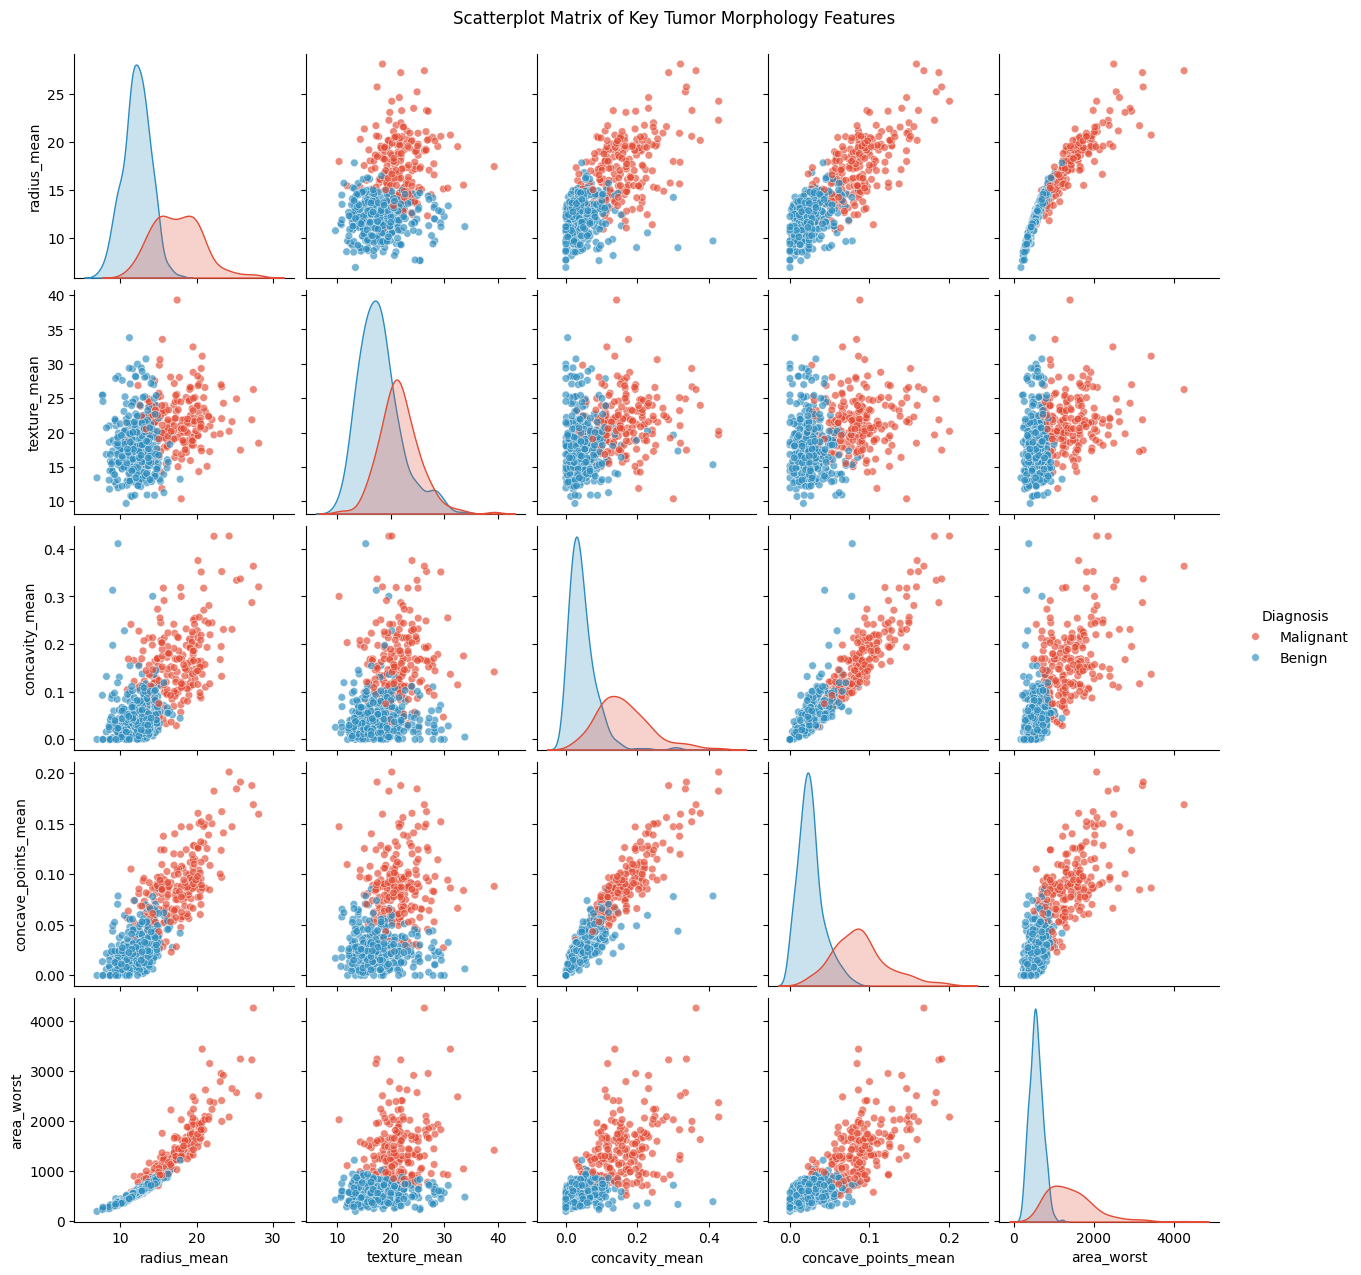

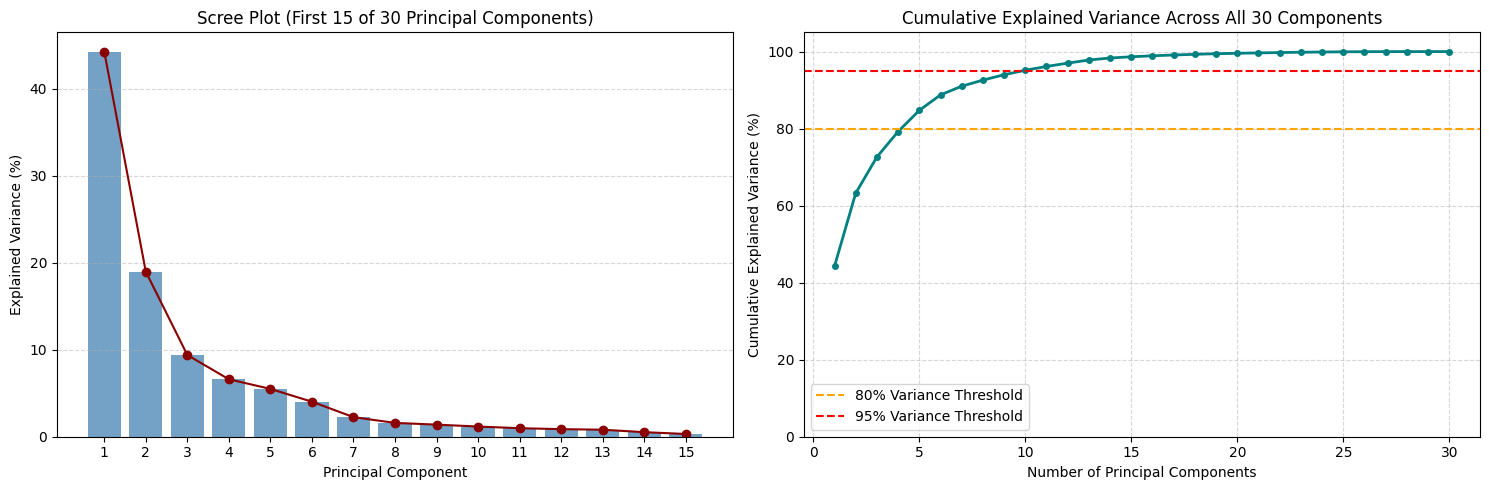

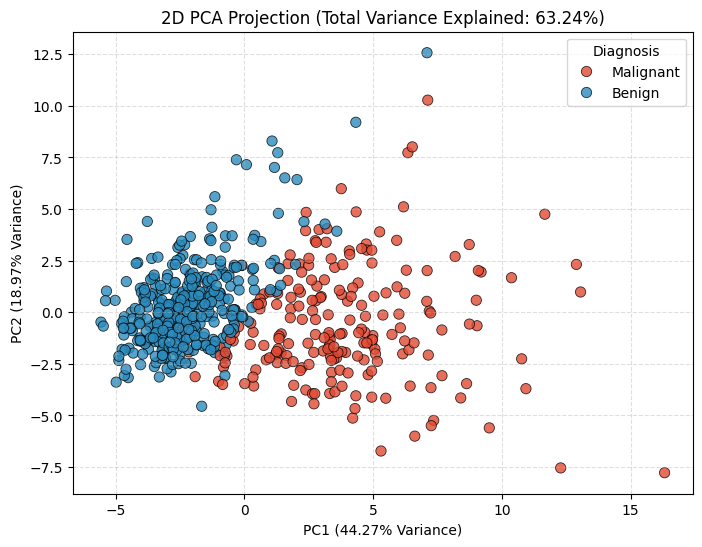

In [3]:
# ==========================================
# TASK 4 (Alternative): High-Dimensional EDA & PCA (Google Colab)
# Dataset: UCI Breast Cancer Wisconsin Diagnostic (30 Features, Direct URL)
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

# 1. Load dataset directly from UCI Repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"

base_features = [
    "radius", "texture", "perimeter", "area", "smoothness",
    "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"
]
feature_cols = (
    [f"{f}_mean" for f in base_features] +
    [f"{f}_se" for f in base_features] +
    [f"{f}_worst" for f in base_features]
)
columns = ["id", "diagnosis_code"] + feature_cols

df = pd.read_csv(url, header=None, names=columns)
df["Diagnosis"] = df["diagnosis_code"].map({"M": "Malignant", "B": "Benign"})
df["diagnosis_num"] = df["diagnosis_code"].map({"B": 0, "M": 1})

X = df[feature_cols]
y = df["Diagnosis"]

print(f"Dataset Shape: {X.shape} (569 samples, 30 continuous features)")
print("Class Distribution:\n", y.value_counts(), "\n")

# 2. Parallel Coordinates Plot (Using the 10 '_mean' features normalized to [0, 1])
mean_cols = [f"{f}_mean" for f in base_features]
scaler_minmax = MinMaxScaler()
df_norm = pd.DataFrame(scaler_minmax.fit_transform(df[mean_cols]), columns=mean_cols)
df_norm["diagnosis_num"] = df["diagnosis_num"]

fig_parallel = px.parallel_coordinates(
    df_norm,
    color="diagnosis_num",
    dimensions=mean_cols,
    color_continuous_scale=[(0.0, "#2b8cbe"), (1.0, "#e34a33")],
    title="Parallel Coordinates Plot: 10 Mean Cell Morphology Features (0 = Benign, 1 = Malignant)"
)
fig_parallel.update_layout(height=550)
fig_parallel.show()

# 3. Scatterplot Matrix (SPLOM) on 5 high-discriminating features
selected_features = [
    "radius_mean", "texture_mean", "concavity_mean",
    "concave_points_mean", "area_worst"
]
pairplot = sns.pairplot(
    df[selected_features + ["Diagnosis"]],
    hue="Diagnosis",
    palette={"Benign": "#2b8cbe", "Malignant": "#e34a33"},
    diag_kind="kde",
    plot_kws={"alpha": 0.65, "s": 30}
)
pairplot.fig.suptitle("Scatterplot Matrix of Key Tumor Morphology Features", y=1.02)
plt.show()

# 4. Standardize all 30 features & Fit Full PCA
scaler_std = StandardScaler()
X_scaled = scaler_std.fit_transform(X)

pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)
explained_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

# 5. Scree Plot & Cumulative Explained Variance Plot (Top 15 Components for readability)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
n_show = 15
components = np.arange(1, n_show + 1)

# Scree Plot
axes[0].bar(components, explained_var[:n_show] * 100, alpha=0.75, color="steelblue", label="Individual Variance")
axes[0].plot(components, explained_var[:n_show] * 100, marker="o", color="darkred")
axes[0].set_title("Scree Plot (First 15 of 30 Principal Components)")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance (%)")
axes[0].set_xticks(components)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Cumulative Explained Variance Plot (All 30 Components)
all_components = np.arange(1, len(explained_var) + 1)
axes[1].plot(all_components, cum_var * 100, marker="o", markersize=4, color="teal", linewidth=2)
axes[1].axhline(80, color="orange", linestyle="--", label="80% Variance Threshold")
axes[1].axhline(95, color="red", linestyle="--", label="95% Variance Threshold")
axes[1].set_title("Cumulative Explained Variance Across All 30 Components")
axes[1].set_xlabel("Number of Principal Components")
axes[1].set_ylabel("Cumulative Explained Variance (%)")
axes[1].set_ylim(0, 105)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# 6. 2D PCA Visualization
pca_2d = PCA(n_components=2)
coords_2d = pca_2d.fit_transform(X_scaled)
df_pca2d = pd.DataFrame(coords_2d, columns=["PC1", "PC2"])
df_pca2d["Diagnosis"] = y

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_pca2d, x="PC1", y="PC2", hue="Diagnosis",
    palette={"Benign": "#2b8cbe", "Malignant": "#e34a33"},
    s=55, alpha=0.8, edgecolor="k"
)
plt.title(
    f"2D PCA Projection (Total Variance Explained: {sum(pca_2d.explained_variance_ratio_)*100:.2f}%)"
)
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.2f}% Variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.2f}% Variance)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

# 7. Interactive 3D PCA Visualization
pca_3d = PCA(n_components=3)
coords_3d = pca_3d.fit_transform(X_scaled)
df_pca3d = pd.DataFrame(coords_3d, columns=["PC1", "PC2", "PC3"])
df_pca3d["Diagnosis"] = y

fig_3d = px.scatter_3d(
    df_pca3d,
    x="PC1", y="PC2", z="PC3",
    color="Diagnosis",
    color_discrete_map={"Benign": "#2b8cbe", "Malignant": "#e34a33"},
    title=f"3D PCA Projection (Total Variance Explained: {sum(pca_3d.explained_variance_ratio_)*100:.2f}%)",
    labels={
        "PC1": f"PC1 ({pca_3d.explained_variance_ratio_[0]*100:.1f}%)",
        "PC2": f"PC2 ({pca_3d.explained_variance_ratio_[1]*100:.1f}%)",
        "PC3": f"PC3 ({pca_3d.explained_variance_ratio_[2]*100:.1f}%)"
    },
    opacity=0.8
)
fig_3d.update_traces(marker=dict(size=4))
fig_3d.show()